# YOLOv5 — Train, Evaluate, and Test on a Custom Image

Designed for **Google Colab**. Select **Runtime → Change runtime type → T4 GPU** (or another GPU) before running.

This notebook downloads the Kaggle dataset, inspects its actual contents, finds or builds a YOLOv5 dataset configuration, trains a pretrained YOLOv5 model, evaluates it, and lets you run inference on your own image.

**Important:** Dataset archives sometimes change. The notebook deliberately inspects the downloaded folder and does not assume the dataset's class names or paths. If no valid dataset YAML exists and the directory layout is unusual, check the inspection output and adjust the configuration cell.


## 1. Check runtime

In [ ]:
import os, sys, glob, shutil, subprocess, textwrap, json
from pathlib import Path

import torch
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. In Colab, select Runtime → Change runtime type → GPU.")


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 2. Upload the dataset ZIP you downloaded from Kaggle

Download the dataset ZIP manually from the Kaggle page, then upload that ZIP when prompted. No Kaggle API token is needed.

If you already extracted the dataset locally, ZIP the dataset folder first, then upload the ZIP here.

In [ ]:
from google.colab import files

DATASET_DIR = Path("/content/weapon_dataset")
DATASET_DIR.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()  # Select the dataset ZIP you downloaded manually
zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
if not zip_names:
    raise ValueError("Please upload the dataset ZIP file downloaded from Kaggle.")

DATASET_ZIP = zip_names[0]
print("Uploaded ZIP:", DATASET_ZIP)

# Extract the archive. Re-running the cell replaces the extraction folder.
shutil.rmtree(DATASET_DIR, ignore_errors=True)
DATASET_DIR.mkdir(parents=True, exist_ok=True)
shutil.unpack_archive(DATASET_ZIP, DATASET_DIR)

print("Extracted to:", DATASET_DIR)
print("Top-level contents:", [p.name for p in DATASET_DIR.iterdir()])

Saving archive (1).zip to archive (1).zip
Uploaded ZIP: archive (1).zip
Extracted to: /content/weapon_dataset
Top-level contents: ['dataset', 'dataset.yaml']


In [ ]:
from google.colab import files
uploaded = files.upload()  # upload kaggle.json

if "kaggle.json" not in uploaded:
    raise FileNotFoundError("Please upload kaggle.json from your Kaggle account.")

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

!pip -q install kaggle


FileNotFoundError: Please upload kaggle.json from your Kaggle account.

In [ ]:
DATASET_SLUG = "raghavnanjappan/weapon-dataset-for-yolov5"
DATASET_ZIP = "/content/weapon-dataset.zip"  # optional manual ZIP path
DATASET_DIR = Path("/content/weapon_dataset")
DATASET_DIR.mkdir(parents=True, exist_ok=True)

if not Path(DATASET_ZIP).exists():
    result = subprocess.run(
        ["kaggle", "datasets", "download", "-d", DATASET_SLUG, "-p", "/content", "-q"],
        text=True, capture_output=True
    )
    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Kaggle download failed. Check your Kaggle token and dataset access.")
    zips = sorted(Path("/content").glob("weapon-dataset-for-yolov5*.zip"),
                  key=lambda p: p.stat().st_mtime, reverse=True)
    if not zips:
        zips = sorted(Path("/content").glob("*.zip"),
                      key=lambda p: p.stat().st_mtime, reverse=True)
    if not zips:
        raise FileNotFoundError("Could not find the downloaded ZIP. Set DATASET_ZIP to your ZIP path.")
    DATASET_ZIP = str(zips[0])

print("ZIP:", DATASET_ZIP)
shutil.unpack_archive(DATASET_ZIP, DATASET_DIR)
print("Extracted to:", DATASET_DIR)


ZIP: /content/weapon-dataset-for-yolov5.zip
Extracted to: /content/weapon_dataset


## 3. Inspect the dataset layout

In [ ]:
# Show a sample of files and any YAML/YML configuration files.
all_files = [p for p in DATASET_DIR.rglob("*") if p.is_file()]
print("Total files:", len(all_files))
print("\nSample files:")
for p in all_files[:80]:
    print(p.relative_to(DATASET_DIR))

yaml_files = list(DATASET_DIR.rglob("*.yaml")) + list(DATASET_DIR.rglob("*.yml"))
print("\nYAML files:")
for p in yaml_files:
    print(p)


Total files: 8315

Sample files:
dataset.yaml
dataset/dataset/labels/val.cache
dataset/dataset/labels/train.cache
dataset/dataset/labels/val/4102.txt
dataset/dataset/labels/val/2062.txt
dataset/dataset/labels/val/4079.txt
dataset/dataset/labels/val/2076.txt
dataset/dataset/labels/val/4093.txt
dataset/dataset/labels/val/2055.txt
dataset/dataset/labels/val/2033.txt
dataset/dataset/labels/val/2013.txt
dataset/dataset/labels/val/4135.txt
dataset/dataset/labels/val/4110.txt
dataset/dataset/labels/val/2061.txt
dataset/dataset/labels/val/2064.txt
dataset/dataset/labels/val/2045.txt
dataset/dataset/labels/val/2001.txt
dataset/dataset/labels/val/2074.txt
dataset/dataset/labels/val/4132.txt
dataset/dataset/labels/val/2019.txt
dataset/dataset/labels/val/2065.txt
dataset/dataset/labels/val/4094.txt
dataset/dataset/labels/val/4123.txt
dataset/dataset/labels/val/2014.txt
dataset/dataset/labels/val/2053.txt
dataset/dataset/labels/val/4151.txt
dataset/dataset/labels/val/4143.txt
dataset/dataset/labels

## 4. Clone YOLOv5 and install requirements

In [ ]:
YOLOV5_DIR = Path("/content/yolov5")
if not YOLOV5_DIR.exists():
    subprocess.run(["git", "clone", "https://github.com/ultralytics/yolov5.git", str(YOLOV5_DIR)], check=True)

%cd /content/yolov5
!pip -q install -r requirements.txt


/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.3 MB/s eta 0:00:00


## 5. Find or configure `data.yaml`

The code below first looks for a YAML file inside the downloaded dataset. If it finds one, it displays it and tries to use it. If no YAML is found, it searches for `images/train` and `images/val` (or equivalent `train/images` and `valid/images` layouts) and builds a config from discovered labels where possible.

**Review the printed class names and paths before training.** If automatic detection cannot infer the classes, edit `CLASS_NAMES_OVERRIDE` in the cell below to match the dataset labels exactly.

In [ ]:
import yaml

# Optional manual override, e.g. ["gun", "knife"]. Leave as None to use a discovered YAML.
CLASS_NAMES_OVERRIDE = None

def read_yaml(path):
    try:
        return yaml.safe_load(Path(path).read_text(encoding="utf-8"))
    except Exception as e:
        print(f"Could not parse {path}: {e}")
        return None

# Prefer a dataset YAML that includes train and val entries.
chosen_yaml = None
for yp in yaml_files:
    cfg = read_yaml(yp)
    if isinstance(cfg, dict) and "train" in cfg and "val" in cfg and ("names" in cfg or "nc" in cfg):
        chosen_yaml = yp
        break

if chosen_yaml:
    print("Using discovered YAML:", chosen_yaml)
    print(chosen_yaml.read_text(encoding="utf-8")[:12000])
else:
    print("No complete dataset YAML found. Searching for train/validation image folders.")


Using discovered YAML: /content/weapon_dataset/dataset.yaml
# Path to the dataset
path: ../dataset  # dataset root dir
train: images/train  # train images (relative to 'path') 4000 images
val: images/val  # val images (relative to 'path') 156 images
test:  # test images (optional)

# Classes
names:
  0: Knife
  1: Handgun



In [ ]:
def has_images(folder):
    if not folder or not Path(folder).exists():
        return False
    return any(p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
               for p in Path(folder).rglob("*") if p.is_file())

# Find common YOLO directory layouts.
candidates = []
for root in [DATASET_DIR] + [p for p in DATASET_DIR.rglob("*") if p.is_dir()]:
    layouts = [
        (root / "images" / "train", root / "images" / "val", root / "images" / "test"),
        (root / "images" / "train", root / "images" / "valid", root / "images" / "test"),
        (root / "train" / "images", root / "valid" / "images", root / "test" / "images"),
        (root / "train" / "images", root / "val" / "images", root / "test" / "images"),
    ]
    for tr, va, te in layouts:
        if has_images(tr) and has_images(va):
            candidates.append((root, tr, va, te if has_images(te) else None))

if not chosen_yaml:
    if not candidates:
        raise RuntimeError(
            "Could not automatically identify train/validation image folders. "
            "Review the file listing above and edit this cell to set TRAIN_IMAGES, VAL_IMAGES, "
            "and class names to match the dataset."
        )
    DATA_ROOT, TRAIN_IMAGES, VAL_IMAGES, TEST_IMAGES = candidates[0]
    print("Detected root:", DATA_ROOT)
    print("Train images:", TRAIN_IMAGES)
    print("Validation images:", VAL_IMAGES)
    print("Test images:", TEST_IMAGES)

    # Try to infer names from existing label folders or label files; otherwise require manual override.
    label_candidates = [
        DATA_ROOT / "labels" / "train",
        DATA_ROOT / "train" / "labels",
        DATA_ROOT / "labels",
    ]
    label_files = []
    for folder in label_candidates:
        if folder.exists():
            label_files = list(folder.glob("*.txt"))[:200]
            if label_files:
                break
    class_ids = set()
    for lf in label_files:
        for line in lf.read_text(errors="ignore").splitlines():
            parts = line.split()
            if parts and parts[0].isdigit():
                class_ids.add(int(parts[0]))
    if CLASS_NAMES_OVERRIDE is not None:
        class_names = list(CLASS_NAMES_OVERRIDE)
    elif class_ids:
        n = max(class_ids) + 1
        class_names = [f"class_{i}" for i in range(n)]
        print("WARNING: class names could not be inferred from labels; set CLASS_NAMES_OVERRIDE to the real names.")
    else:
        raise RuntimeError("No YOLO label files found. This dataset may need annotation/conversion before training.")

    config = {
        "path": str(DATA_ROOT),
        "train": str(Path(TRAIN_IMAGES).relative_to(DATA_ROOT)),
        "val": str(Path(VAL_IMAGES).relative_to(DATA_ROOT)),
        "names": {i: name for i, name in enumerate(class_names)}
    }
    if TEST_IMAGES:
        config["test"] = str(Path(TEST_IMAGES).relative_to(DATA_ROOT))
    DATA_YAML = Path("/content/yolov5_weapon_data.yaml")
    DATA_YAML.write_text(yaml.safe_dump(config, sort_keys=False), encoding="utf-8")
else:
    # Make a copy and normalize root path so relative paths resolve reliably.
    cfg = read_yaml(chosen_yaml)
    root = Path(cfg.get("path", chosen_yaml.parent))
    if not root.is_absolute():
        root = (chosen_yaml.parent / root).resolve()
    cfg["path"] = str(root)
    if CLASS_NAMES_OVERRIDE is not None:
        cfg["names"] = {i: n for i, n in enumerate(CLASS_NAMES_OVERRIDE)}
        cfg["nc"] = len(CLASS_NAMES_OVERRIDE)
    DATA_YAML = Path("/content/yolov5_weapon_data.yaml")
    DATA_YAML.write_text(yaml.safe_dump(cfg, sort_keys=False), encoding="utf-8")

print("\nFinal dataset YAML:", DATA_YAML)
print(DATA_YAML.read_text())



Final dataset YAML: /content/yolov5_weapon_data.yaml
path: /content/dataset
train: images/train
val: images/val
test: null
names:
  0: Knife
  1: Handgun



## 6. Sanity-check image and label counts

In [ ]:
cfg = yaml.safe_load(DATA_YAML.read_text())
root = Path(cfg.get("path", DATASET_DIR))

def resolve_data_entry(entry):
    if not entry:
        return None
    if isinstance(entry, list):
        return [resolve_data_entry(x) for x in entry]
    p = Path(entry)
    return p if p.is_absolute() else root / p

for split in ("train", "val", "test"):
    entry = resolve_data_entry(cfg.get(split))
    if entry is None:
        continue
    entries = entry if isinstance(entry, list) else [entry]
    count = 0
    for e in entries:
        if e.is_dir():
            count += sum(p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"} for p in e.rglob("*"))
        elif e.is_file() and e.suffix.lower() == ".txt":
            count += len([x for x in e.read_text().splitlines() if x.strip()])
    print(f"{split}: {count} images/entries")

print("Classes:", cfg.get("names"))


train: 0 images/entries
val: 0 images/entries
Classes: {0: 'Knife', 1: 'Handgun'}


## 7. Train YOLOv5s

Start with a small run to verify the pipeline. Increase `EPOCHS` after confirming the dataset paths, labels, and class names.

In [ ]:
EPOCHS = 30
IMG_SIZE = 640
BATCH_SIZE = 16 if torch.cuda.is_available() else 4
WEIGHTS = "yolov5s.pt"
RUN_NAME = "weapon_yolov5s"

train_cmd = [
    sys.executable, "train.py",
    "--img", str(IMG_SIZE),
    "--batch", str(BATCH_SIZE),
    "--epochs", str(EPOCHS),
    "--data", str(DATA_YAML),
    "--weights", WEIGHTS,
    "--name", RUN_NAME,
    "--project", "/content/runs/train",
    "--exist-ok",
    "--workers", "2"
]
print("Running:", " ".join(train_cmd))
subprocess.run(train_cmd, check=True)



Running: /usr/bin/python3 train.py --img 640 --batch 16 --epochs 30 --data /content/yolov5_weapon_data.yaml --weights yolov5s.pt --name weapon_yolov5s --project /content/runs/train --exist-ok --workers 2


CompletedProcess(args=['/usr/bin/python3', 'train.py', '--img', '640', '--batch', '16', '--epochs', '30', '--data', '/content/yolov5_weapon_data.yaml', '--weights', 'yolov5s.pt', '--name', 'weapon_yolov5s', '--project', '/content/runs/train', '--exist-ok', '--workers', '2'], returncode=0)

## 8. Evaluate on the validation set

In [ ]:
BEST_WEIGHTS = Path("/content/runs/train") / RUN_NAME / "weights" / "best.pt"
if not BEST_WEIGHTS.exists():
    raise FileNotFoundError(f"Best checkpoint not found: {BEST_WEIGHTS}")

val_cmd = [
    sys.executable, "val.py",
    "--data", str(DATA_YAML),
    "--weights", str(BEST_WEIGHTS),
    "--img", str(IMG_SIZE),
    "--batch-size", str(BATCH_SIZE),
    "--task", "val",
    "--project", "/content/runs/val",
    "--name", RUN_NAME,
    "--exist-ok"
]
subprocess.run(val_cmd, check=True)


CompletedProcess(args=['/usr/bin/python3', 'val.py', '--data', '/content/yolov5_weapon_data.yaml', '--weights', '/content/runs/train/weapon_yolov5s/weights/best.pt', '--img', '640', '--batch-size', '16', '--task', 'val', '--project', '/content/runs/val', '--name', 'weapon_yolov5s', '--exist-ok'], returncode=0)

## 9. Test split evaluation (if the dataset provides one)

In [ ]:
cfg = yaml.safe_load(DATA_YAML.read_text())
if cfg.get("test"):
    test_cmd = [
        sys.executable, "val.py",
        "--data", str(DATA_YAML),
        "--weights", str(BEST_WEIGHTS),
        "--img", str(IMG_SIZE),
        "--batch-size", str(BATCH_SIZE),
        "--task", "test",
        "--project", "/content/runs/test",
        "--name", RUN_NAME,
        "--exist-ok"
    ]
    subprocess.run(test_cmd, check=True)
else:
    print("No test split configured. Validation metrics above are not test-set metrics.")


No test split configured. Validation metrics above are not test-set metrics.


## 10. Visualize validation predictions

Saved predictions: /content/runs/predict/validation_examples | images: 156


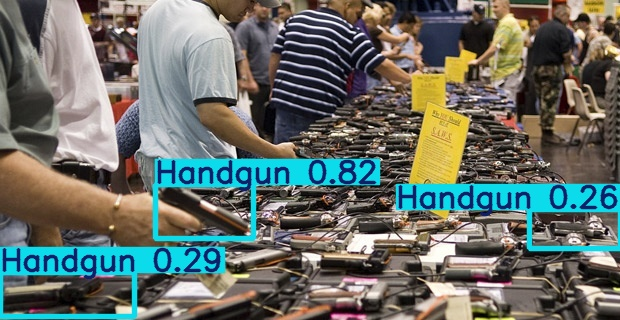

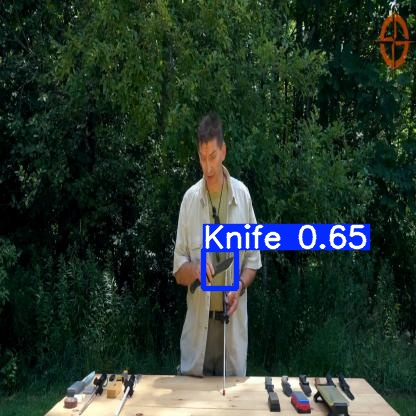

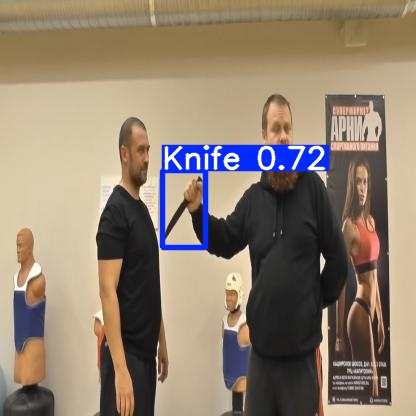

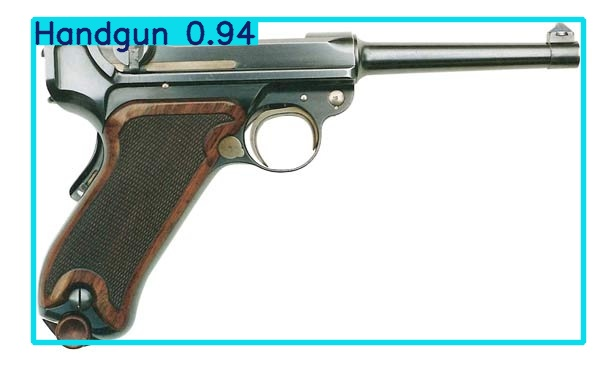

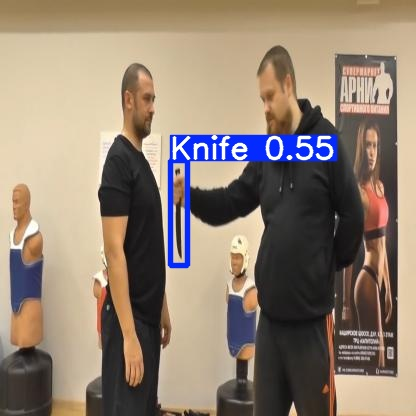

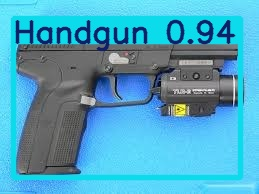

In [ ]:
from IPython.display import display, Image as IPyImage

val_pred_cmd = [
    sys.executable, "detect.py",
    "--weights", str(BEST_WEIGHTS),
    "--source", str(resolve_data_entry(cfg["val"])),
    "--img", str(IMG_SIZE),
    "--conf-thres", "0.25",
    "--project", "/content/runs/predict",
    "--name", "validation_examples",
    "--exist-ok",
    "--save-txt"
]
subprocess.run(val_pred_cmd, check=True)

pred_dir = Path("/content/runs/predict/validation_examples")
pred_images = [p for p in pred_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
print("Saved predictions:", pred_dir, "| images:", len(pred_images))
for p in pred_images[:6]:
    display(IPyImage(filename=str(p)))


## 11. Run the trained model on your own image

Run this cell and upload an image from your computer. The annotated result will be displayed and saved under `/content/runs/predict/custom_image/`.

In [ ]:
from google.colab import files
from IPython.display import display, Image as IPyImage

uploaded_image = files.upload()
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_paths = [Path(name) for name in uploaded_image if Path(name).suffix.lower() in image_exts]
if not image_paths:
    raise ValueError("Upload an image file: JPG, JPEG, PNG, BMP, or WEBP.")

custom_source = str(image_paths[0])
custom_cmd = [
    sys.executable, "detect.py",
    "--weights", str(BEST_WEIGHTS),
    "--source", custom_source,
    "--img", str(IMG_SIZE),
    "--conf-thres", "0.25",
    "--project", "/content/runs/predict",
    "--name", "custom_image",
    "--exist-ok",
    "--save-conf"
]
subprocess.run(custom_cmd, check=True)

result_path = Path("/content/runs/predict/custom_image") / Path(custom_source).name
if result_path.exists():
    display(IPyImage(filename=str(result_path)))
    print("Result saved to:", result_path)
else:
    outputs = [p for p in Path("/content/runs/predict/custom_image").glob("*") if p.suffix.lower() in image_exts]
    if outputs:
        display(IPyImage(filename=str(outputs[0])))
        print("Result saved to:", outputs[0])
    else:
        print("Inference finished; check /content/runs/predict/custom_image")


ValueError: Upload an image file: JPG, JPEG, PNG, BMP, or WEBP.

## 12. Download trained weights

In [ ]:
from google.colab import files
files.download(str(BEST_WEIGHTS))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
from pathlib import Path

weights = Path("/content/yolov5/runs/train/exp/weights/best.pt")

# Find the checkpoint if your run has a different name
if not weights.exists():
    matches = list(Path("/content/runs/train").rglob("best.pt"))
    if not matches:
        matches = list(Path("/content/yolov5/runs/train").rglob("best.pt"))
    print("Found:", matches)
    if matches:
        weights = matches[-1]

files.download(str(weights))

In [ ]:
import shutil
from google.colab import files

folder = "/content/runs"

shutil.make_archive(
    "/content/runs_export",
    "zip",
    folder
)

files.download("/content/runs_export.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes
- Training outputs and metrics are saved under `/content/runs/`.
- Colab storage is temporary. Download `best.pt` (and optionally the run folder) before the runtime disconnects.
- If training reports that labels are missing or class IDs are out of range, verify that labels are YOLO-format `.txt` files and that `names` matches the class IDs.
- Only use the detector for lawful, safety-oriented purposes. Predictions are not proof that an object is a weapon; review false positives and false negatives.
- Official YOLOv5 custom-training guide: https://docs.ultralytics.com/yolov5/tutorials/train-custom-data
